# Params walkthrough

Goes through the output of `src.params.build_inputs` for one rebalance date. Run from the repo root or `workbook/`. See `src/params/README.md` for definitions. POC: MBS inputs are rough.

In [1]:
import os, sys
os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "workbook" else os.getcwd())
sys.path.insert(0, os.getcwd())
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from data_cleaning import config as C
from src.params import build_inputs, load_data, tracking_variance
pd.options.display.float_format = "{:,.4f}".format

data = load_data()
ASOF, W = "2025-06-30", 1_000_000
G, N = W * 1.05 ** 2, 24          # example goal: 5% a year over 2 years, 24 monthly rebalances
P = build_inputs(ASOF, W, H=2, G=G, t_index=0, N=N, data=data)
p0, p1 = P.periods
n = len(P.cusips)
print(f"{P.asof.date()}: {n} bonds, H={len(P.periods)}")
pd.Series(P.sector).value_counts().to_frame("bonds").assign(b_weight=pd.Series(P.b, index=P.sector).groupby(level=0).sum())

2025-06-30: 8531 bonds, H=2


,bonds,b_weight
industrial,4072,0.1689
financial,1832,0.0948
utility,1223,0.0316
mbs_passthrough,1178,0.2108
treasury,226,0.4939


## 1. Key-rate covariance (Sigma) and curve factors

Monthly changes of the 8 fitted zero yields up to `asof`, Ledoit-Wolf estimate, top 3 principal components.

T_s (observations): 17 | explained: [0.83  0.078 0.025] | total 0.932


,6M,1Y,2Y,3Y,5Y,7Y,10Y,30Y
bp^2 per month,,,,,,,,
6M,259,265,278,259,227,203,177,74
1Y,265,484,505,502,465,425,374,176
2Y,278,505,733,706,681,629,561,286
3Y,259,502,706,821,750,699,628,333
5Y,227,465,681,750,819,719,657,361
7Y,203,425,629,699,719,751,643,358
10Y,177,374,561,628,657,643,671,346
30Y,74,176,286,333,361,358,346,289


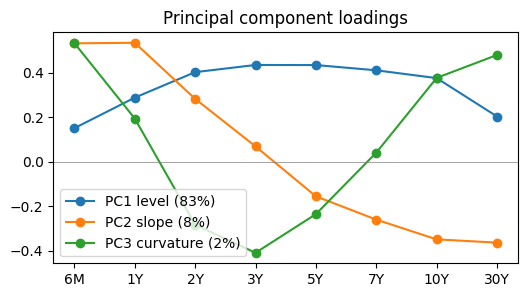

In [2]:
m = P.model
labels = list(C.KEY_RATES)
print("T_s (observations):", m.n_obs, "| explained:", np.round(m.explained, 3), "| total", round(m.explained.sum(), 3))
display(pd.DataFrame((m.Sigma * 1e8).astype(int), index=labels, columns=labels).round(0).rename_axis("bp^2 per month"))
fig, ax = plt.subplots(figsize=(6, 3))
for j, nm in enumerate(["PC1 level", "PC2 slope", "PC3 curvature"]):
    ax.plot(labels, m.Gamma[:, j], marker="o", label=f"{nm} ({m.explained[j]:.0%})")
ax.axhline(0, c="grey", lw=.5); ax.legend(); ax.set_title("Principal component loadings"); plt.show()

## 2. Bond sensitivities (K, D, D_spr, C, dts)

Each bond is repriced off the fitted curve plus its own spread. K is 1 bp triangular bump per key rate, so a bond's K row sums to its duration.

In [3]:
type(p0)

src.params.inputs.PeriodInputs

max |sum(K) - D|: 0.0085 | D_spr == D: True


,bonds,D,C,dts
sector,,,,
financial,1832,6.0125,39.1667,0.0534
industrial,4072,7.3398,62.6654,0.0632
mbs_passthrough,1178,14.3749,281.3933,-0.0768
treasury,226,5.7684,35.6182,0.0001
utility,1223,10.0322,126.2406,0.0927


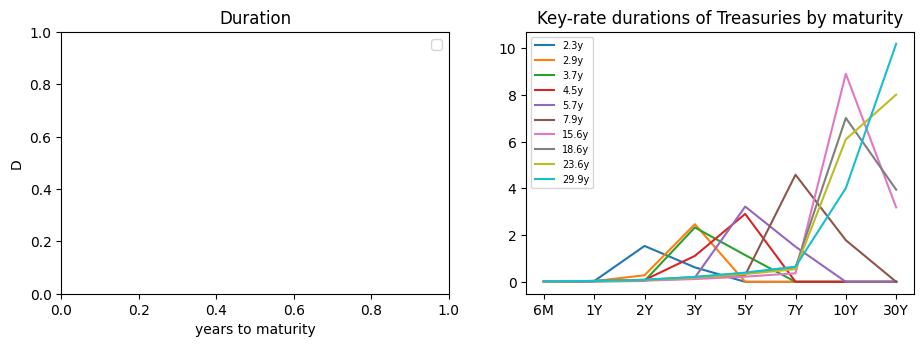

In [3]:
meta = pd.DataFrame({"sector": P.sector, "D": p0.D, "D_spr": p0.D_spr, "C": p0.C, "dts": p0.dts, "sumK": p0.K.sum(1),
                     "b": P.b, "spread_solved": P.spread_solved}, index=P.cusips)
print("max |sum(K) - D|:", np.abs(meta.sumK - meta.D).max().round(4), "| D_spr == D:", np.allclose(meta.D, meta.D_spr))
display(meta.groupby("sector").agg(bonds=("D", "size"), D=("D", "median"), C=("C", "median"), dts=("dts", "median")))
mat = data.universe.set_index("cusip").reindex(P.cusips)
yrs = ((mat.maturity_date - P.asof).dt.days / 365.25).to_numpy()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for s in []:
    k = P.sector == s; axs[0].scatter(yrs[k], p0.D[k], s=4, alpha=.5, label=s)
axs[0].set(xlabel="years to maturity", ylabel="D", title="Duration"); axs[0].legend()
tsy = np.flatnonzero(P.sector == "treasury"); tsy = tsy[np.argsort(yrs[tsy])][::25]
for i in tsy: axs[1].plot(labels, p0.K[i], label=f"{yrs[i]:.1f}y")
axs[1].set(title="Key-rate durations of Treasuries by maturity"); axs[1].legend(fontsize=7); plt.show()

In [5]:
# Treasury duration vs CRSP's own duration
t = pd.read_parquet(C.PROCESSED_DIR / "treasury_daily.parquet"); t = t[t.date == P.asof].set_index("cusip")["duration"]
k = P.sector == "treasury"; ours = pd.Series(p0.D[k], index=P.cusips[k])
print("corr with CRSP duration:", round(ours.corr(t.reindex(ours.index)), 5))

corr with CRSP duration: 0.99992


## 3. Residual variance (psi) and the factor form of Q

Q = F F' + diag(psi), F = K Gamma Lambda^(1/2). Q is never formed. Below: tracking variance of an example portfolio (the 50 largest bonds, benchmark-weighted) against the benchmark.

In [4]:
print("F shape:", p0.F.shape)
display(pd.DataFrame({"psi": m.psi, "n_obs": P.n_resid_obs, "sector": P.sector}).groupby("sector").agg(
    psi_median=("psi", "median"), obs_median=("n_obs", "median")))
top = np.argsort(-P.b)[:50]
x = np.zeros(n); x[top] = P.b[top]; x /= x.sum()
a = x - P.b
tv = tracking_variance(p0.F, m.psi, a)
fac = np.sum((p0.F.T @ a) ** 2)
print(f"tracking vol: {np.sqrt(tv):.3%}/month, {np.sqrt(12*tv):.2%}/year | share from curve factors {fac/tv:.0%}, residual {1-fac/tv:.0%}")
print("duration gap D'a:", round(p0.D @ a, 3), "| factor exposures F'a:", np.round(p0.F.T @ a, 4))

F shape: (8531, 3)


,psi_median,obs_median
sector,,
financial,0.0001,17.0000
industrial,0.0001,17.0000
mbs_passthrough,0.0006,1.0000
treasury,0.0000,17.0000
utility,0.0001,17.0000


tracking vol: 0.542%/month, 1.88%/year | share from curve factors 98%, residual 2%
duration gap D'a: -3.088 | factor exposures F'a: [-0.0043  0.0025 -0.002 ]


## 4. Forecasts, one period ahead (mu_hat, b_hat, exits)

mu_hat is carry plus roll-down from repricing one month ahead on a constant curve.

In [5]:
f = pd.DataFrame({"sector": P.sector, "mu_hat": p0.mu_hat, "b": P.b, "b_hat_h1": p1.b_hat})
display(f.groupby("sector").agg(mu_hat_median=("mu_hat", "median"), b=("b", "sum"), b_hat_h1=("b_hat_h1", "sum")))
print(f"benchmark forecast return: {p0.b_hat @ p0.mu_hat:.3%}/month ({(1 + p0.b_hat @ p0.mu_hat) ** 12 - 1:.2%}/year)")
print("exits h0 / h1:", p0.exits.sum(), p1.exits.sum(), "| sum b_hat:", p0.b_hat.sum().round(6), p1.b_hat.sum().round(6))

,mu_hat_median,b,b_hat_h1
sector,,,
financial,0.0046,0.0948,0.0948
industrial,0.0047,0.1689,0.1690
mbs_passthrough,0.0038,0.2108,0.2109
treasury,0.0038,0.4939,0.4937
utility,0.0049,0.0316,0.0316


benchmark forecast return: 0.402%/month (4.94%/year)
exits h0 / h1: 0 0 | sum b_hat: 1.0 1.0


## 5. Multi-period: what changes with h

Bonds are aged one month under the same curve. Sigma and psi are fixed. `drift_gross` and `r_b` feed the x_tilde link between periods.

In [6]:
rows = []
for q in P.periods:
    rows.append({"h": q.h, "date": q.date.date(), "bench D": q.b_hat @ q.D, "bench C": q.b_hat @ q.C,
                 "bench mu": q.b_hat @ q.mu_hat, "wealth": q.wealth, "r_req": q.r_req, "r_b": q.r_b,
                 "median ell": np.median(q.ell), "exits": int(q.exits.sum())})
display(pd.DataFrame(rows).set_index("h"))
d = p1.b_hat - p0.b_hat
print("weight moved by drift (half L1):", round(np.abs(d).sum() / 2, 5))
# x_tilde link: hold the benchmark at h=0, see where drift takes it
xt = p1.drift_gross * p0.b_hat / (1 + p1.r_b)
print("x_tilde sums to", xt.sum().round(6), "| max |x_tilde - b_hat_h1|:", np.abs(xt - p1.b_hat).max().round(6),
      "(differs only by exits/renormalisation)")

,date,bench D,bench C,bench mu,wealth,r_req,r_b,median ell,exits
h,,,,,,,,,
0,2025-06-30,8.5328,133.0055,0.0040,"1,000,000.0000",0.0041,NaN,0.0019,0
1,2025-07-31,8.4685,131.8838,0.0040,"1,004,024.4312",0.0041,0.0040,0.0019,0


weight moved by drift (half L1): 0.00033
x_tilde sums to 1.0 | max |x_tilde - b_hat_h1|: 0.0 (differs only by exits/renormalisation)


## 6. Frictions and goal

Trading cost c is half the bid-ask spread. ell is the minimum lot as a weight of wealth. r_req is the per-period return the goal needs.

In [7]:
fr = pd.DataFrame({"sector": P.sector, "c_bps": P.c * 1e4, "ell": p0.ell})
display(fr.groupby("sector").agg(c_bps_median=("c_bps", "median"), ell_median=("ell", "median"), ell_max=("ell", "max")))
print(f"G = {G:,.0f}, W = {W:,.0f}, N = {N}: r_req = {p0.r_req:.3%}/month ({(1+p0.r_req)**12-1:.2%}/year) vs forecast benchmark {p0.b_hat @ p0.mu_hat:.3%}/month")
print("bonds with ell > 1% of wealth:", int((p0.ell > .01).sum()))

,c_bps_median,ell_median,ell_max
sector,,,
financial,5.4817,0.0020,0.2767
industrial,6.2384,0.0019,0.2440
mbs_passthrough,5.9294,0.0018,0.0021
treasury,2.3921,0.0001,0.0001
utility,8.1559,0.0017,0.8553


G = 1,102,500, W = 1,000,000, N = 24: r_req = 0.407%/month (5.00%/year) vs forecast benchmark 0.402%/month
bonds with ell > 1% of wealth: 374


## 7. Data quality flags

In [10]:
q = pd.DataFrame({"sector": P.sector, "stale": P.stale, "spread_solved": P.spread_solved, "psi_obs<6": P.n_resid_obs < 6})
display(q.groupby("sector").mean().mul(100).round(1).rename_axis("% of bonds"))

,stale,spread_solved,psi_obs<6
% of bonds,,,
financial,0.6000,0.0000,11.5000
industrial,1.6000,0.0000,9.5000
mbs_passthrough,100.0000,100.0000,73.4000
treasury,0.0000,0.0000,10.2000
utility,2.1000,0.0000,8.2000


## 8. Optimization ##

In [ ]:
from src import optimization
import numpy as np
from scipy import sparse as sp

periods = P.periods
H = len(periods)
n = len(P.cusips)
loose_limit = 1e6

theta_half = sp.vstack((
    sp.csc_matrix(P.theta_F.T),
    sp.diags(np.sqrt(P.theta_psi), format="csc"),
), format="csc")

optimizer_inputs = {
    "H": H,
    "n": n,
    "omega": np.ones(H),
    "c": P.c,
    "F": [q.F for q in periods],
    "psi": P.model.psi,
    "b": [q.b_hat for q in periods],
    "R": [sp.eye(n, format="csc")] + [
        sp.diags(q.drift_gross, format="csc") for q in periods[1:]
    ],
    "r_b": [0.0] + [q.r_b for q in periods[1:]],
    "x_init": np.zeros(n),
    "D": [q.D for q in periods],
    "K": [q.K for q in periods],
    "D_spr": [q.D_spr for q in periods],
    "C": [q.C for q in periods],
    "delta_D": loose_limit,
    "delta_K": loose_limit,
    "delta_S": loose_limit,
    "delta_C": loose_limit,
    "mu": [q.mu_hat for q in periods],
    "eps2": 0.2,
    "Theta_half": [theta_half] * H,
    "r_req": [q.r_req for q in periods],
    "l": [q.ell for q in periods],
    "E": [np.flatnonzero(q.exits) for q in periods],
    "k_max": 100
}

opt_object = optimization.GoalPathBondOptimizer(**optimizer_inputs)

In [ ]:
result = opt_object.optimize()

                                     CVXPY                                     
                                     v1.6.3                                    
(CVXPY) Nov 17 10:01:30 AM: Your problem has 102372 variables, 85338 constraints, and 0 parameters.
(CVXPY) Nov 17 10:01:30 AM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Nov 17 10:01:30 AM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Nov 17 10:01:30 AM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Nov 17 10:01:30 AM: Your problem is compiled with the CPP canonicalization backend.
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
(CVXPY) Nov 17 10:01:30 AM: Compiling problem (target solver=GUR

(CVXPY) Nov 17 10:01:30 AM: Applying reduction CvxAttr2Constr
(CVXPY) Nov 17 10:01:30 AM: Applying reduction ConeMatrixStuffing
(CVXPY) Nov 17 10:01:31 AM: Applying reduction GUROBI
(CVXPY) Nov 17 10:01:32 AM: Finished problem compilation (took 1.129e+00 seconds).
-------------------------------------------------------------------------------
                                Numerical solver                               
-------------------------------------------------------------------------------
(CVXPY) Nov 17 10:01:32 AM: Invoking solver GUROBI  to obtain a solution.
Set parameter Username
Set parameter LicenseID to value 2885673
Academic license - for non-commercial use only - expires 2027-11-17
Set parameter OutputFlag to value 1
Set parameter QCPDual to value 1
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11+.0 (26300.2))

CPU model: Intel(R) Core(TM) Ultra 7 155H, instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 22 logical processors, using

: 